## Підготовка середовища ##

In [1]:
from pathlib import Path

import json
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

SEED = 42

HEAD_EPOCHS, FINE_EPOCHS = 10, 10

keras.utils.set_random_seed(SEED)

OUT = Path("lab10_results")
OUT.mkdir(exist_ok=True)

print(tf.__version__, keras.__version__)

2.21.0 3.15.1


## Підготувка каталогів ##

In [17]:
DATA_DIR = Path(r"E:\Datasets\food101_lab9")

for split in ["train", "val", "test"]:
    print(f"{split}:",
          [p.name for p in (DATA_DIR / split).iterdir()])

train: ['chicken_quesadilla', 'grilled_cheese_sandwich', 'prime_rib']
val: ['chicken_quesadilla', 'grilled_cheese_sandwich', 'prime_rib']
test: ['chicken_quesadilla', 'grilled_cheese_sandwich', 'prime_rib']


## Завантаження датасетів ##

In [20]:
common = dict(
    image_size=(224, 224),
    batch_size=32,
    label_mode="int"
)

train_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    shuffle=True,
    seed=SEED,
    **common
)

class_names = train_raw.class_names
num_classes = len(class_names)

assert num_classes >= 2

val_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "val",
    class_names=class_names,
    shuffle=False,
    **common
)

test_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    class_names=class_names,
    shuffle=False,
    **common
)

Found 1800 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 750 files belonging to 3 classes.


## Створення Dataset ##

In [21]:
train_ds = train_raw.prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.prefetch(tf.data.AUTOTUNE)
test_ds = test_raw.prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))

print(class_names, images.shape, images.dtype)

print(
    float(tf.reduce_min(images)),
    float(tf.reduce_max(images))
)

['chicken_quesadilla', 'grilled_cheese_sandwich', 'prime_rib'] (32, 224, 224, 3) <dtype: 'float32'>
0.0 255.0


## Побудова моделі EfficientNetB0 ##

In [25]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED + 1),
], name="augmentation")
base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet",
    input_shape=(224, 224, 3))
base_model.trainable = False
inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = keras.Model(inputs, outputs)
 
def trainable_count(m):
    return int(sum(np.prod(v.shape) for v in m.trainable_weights))
 
def compile_model(m, learning_rate):
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(
            name="accuracy")])
 
compile_model(model, 1e-3)
head_params = trainable_count(model)
model.summary(show_trainable=True)
print("Навчуваних параметрів:", head_params)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_2 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Навчуваних параметрів: 3843


## Навчання нового класифікатора ##

In [26]:
def callbacks(stage):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3,
            restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(
            str(OUT / f"{stage}.keras"),
            monitor="val_loss", save_best_only=True),
    ]
 
history_head = model.fit(
    train_ds, validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks("feature_extraction"),
    shuffle=False)
 
head_model = keras.models.load_model(
    OUT / "feature_extraction.keras")
head_val = head_model.evaluate(
    val_ds, return_dict=True, verbose=0)
model.set_weights(head_model.get_weights())
del head_model
print("Feature extraction:", head_val)


Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 68s 992ms/step - accuracy: 0.7800 - loss: 0.6216 - val_accuracy: 0.9200 - val_loss: 0.3241
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 49s 863ms/step - accuracy: 0.9056 - loss: 0.3137 - val_accuracy: 0.9378 - val_loss: 0.2334
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 50s 886ms/step - accuracy: 0.9328 - loss: 0.2361 - val_accuracy: 0.9467 - val_loss: 0.1984
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 50s 875ms/step - accuracy: 0.9328 - loss: 0.2176 - val_accuracy: 0.9489 - val_loss: 0.1814
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 51s 899ms/step - accuracy: 0.9500 - loss: 0.1844 - val_accuracy: 0.9467 - val_loss: 0.1678
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 48s 851ms/step - accuracy: 0.9483 - loss: 0.1754 - val_accuracy: 0.9556 - val_loss: 0.1614
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 49s 867ms/step - accuracy: 0.9539 - loss: 0.1596 - val_accuracy: 0.9511 - val_loss: 0.1571
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 51s 890ms/step - accuracy: 0.9528 - loss: 0.1508 - val_accu

## часткове донавчання EfficientNetB0 ##

In [28]:
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith(("block7", "top_"))
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
 
fine_params = trainable_count(model)
assert fine_params > head_params
print([layer.name for layer in base_model.layers
       if layer.trainable_weights])
compile_model(model, 1e-5)
history_fine = model.fit(
    train_ds, validation_data=val_ds,
    epochs=FINE_EPOCHS,
    callbacks=callbacks("fine_tuning"),
    shuffle=False)
fine_model = keras.models.load_model(OUT / "fine_tuning.keras")
fine_val = fine_model.evaluate(
    val_ds, return_dict=True, verbose=0)
del fine_model
print("Fine-tuning:", fine_val)


['block7a_expand_conv', 'block7a_dwconv', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_project_conv', 'top_conv']
Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 69s 991ms/step - accuracy: 0.9561 - loss: 0.1371 - val_accuracy: 0.9533 - val_loss: 0.1410
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 54s 947ms/step - accuracy: 0.9628 - loss: 0.1254 - val_accuracy: 0.9556 - val_loss: 0.1391
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 56s 981ms/step - accuracy: 0.9633 - loss: 0.1158 - val_accuracy: 0.9578 - val_loss: 0.1353
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 54s 951ms/step - accuracy: 0.9589 - loss: 0.1188 - val_accuracy: 0.9578 - val_loss: 0.1328
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 50s 874ms/step - accuracy: 0.9589 - loss: 0.1196 - val_accuracy: 0.9578 - val_loss: 0.1329
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 50s 873ms/step - accuracy: 0.9650 - loss: 0.1099 - val_accuracy: 0.9556 - val_loss: 0.1306
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 56s 977ms/step - accuracy: 0.9656 - loss: 0.1023 - val_accuracy: 0.9

## Вибір моделі та підсумкова оцінка ##

In [29]:
comparison = [
    {"stage": "feature_extraction", "lr": 1e-3,
     "params": head_params,
     "epochs": len(history_head.history["loss"]), **head_val},
    {"stage": "fine_tuning", "lr": 1e-5,
     "params": fine_params,
     "epochs": len(history_fine.history["loss"]), **fine_val},
]
for row in comparison:
    print(row)
selected_stage = ("fine_tuning"
    if fine_val["loss"] < head_val["loss"]
    else "feature_extraction")
best_model = keras.models.load_model(
    OUT / f"{selected_stage}.keras")
print("Обрано:", selected_stage)
 
test_metrics = best_model.evaluate(
    test_ds, return_dict=True, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilities = best_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)
print(test_metrics)
print(classification_report(
    y_true, y_pred, labels=np.arange(num_classes),
    target_names=class_names, digits=3, zero_division=0))


{'stage': 'feature_extraction', 'lr': 0.001, 'params': 3843, 'epochs': 10, 'accuracy': 0.9511111378669739, 'loss': 0.14249823987483978}
{'stage': 'fine_tuning', 'lr': 1e-05, 'params': 1125427, 'epochs': 10, 'accuracy': 0.9577777981758118, 'loss': 0.12736336886882782}
Обрано: fine_tuning
{'accuracy': 0.95333331823349, 'loss': 0.10339420288801193}
                         precision    recall  f1-score   support

     chicken_quesadilla      0.941     0.960     0.950       250
grilled_cheese_sandwich      0.954     0.920     0.937       250
              prime_rib      0.965     0.980     0.972       250

               accuracy                          0.953       750
              macro avg      0.953     0.953     0.953       750
           weighted avg      0.953     0.953     0.953       750



## Візуалізація та аналіз помилок ##

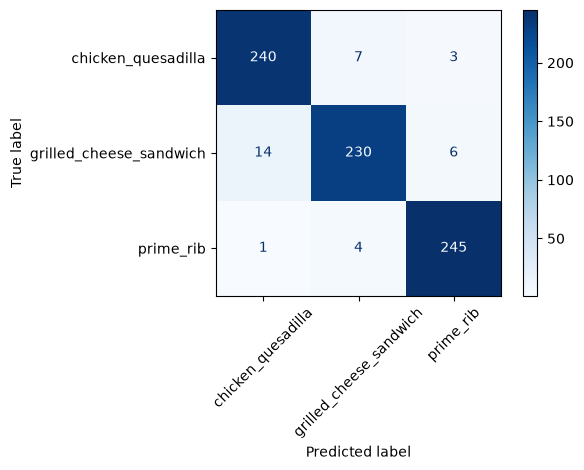

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=np.arange(num_classes),
    display_labels=class_names, xticks_rotation=45,
    cmap="Blues")
plt.tight_layout()
plt.show()

 ## Перегляд помилкових прогнозів ##

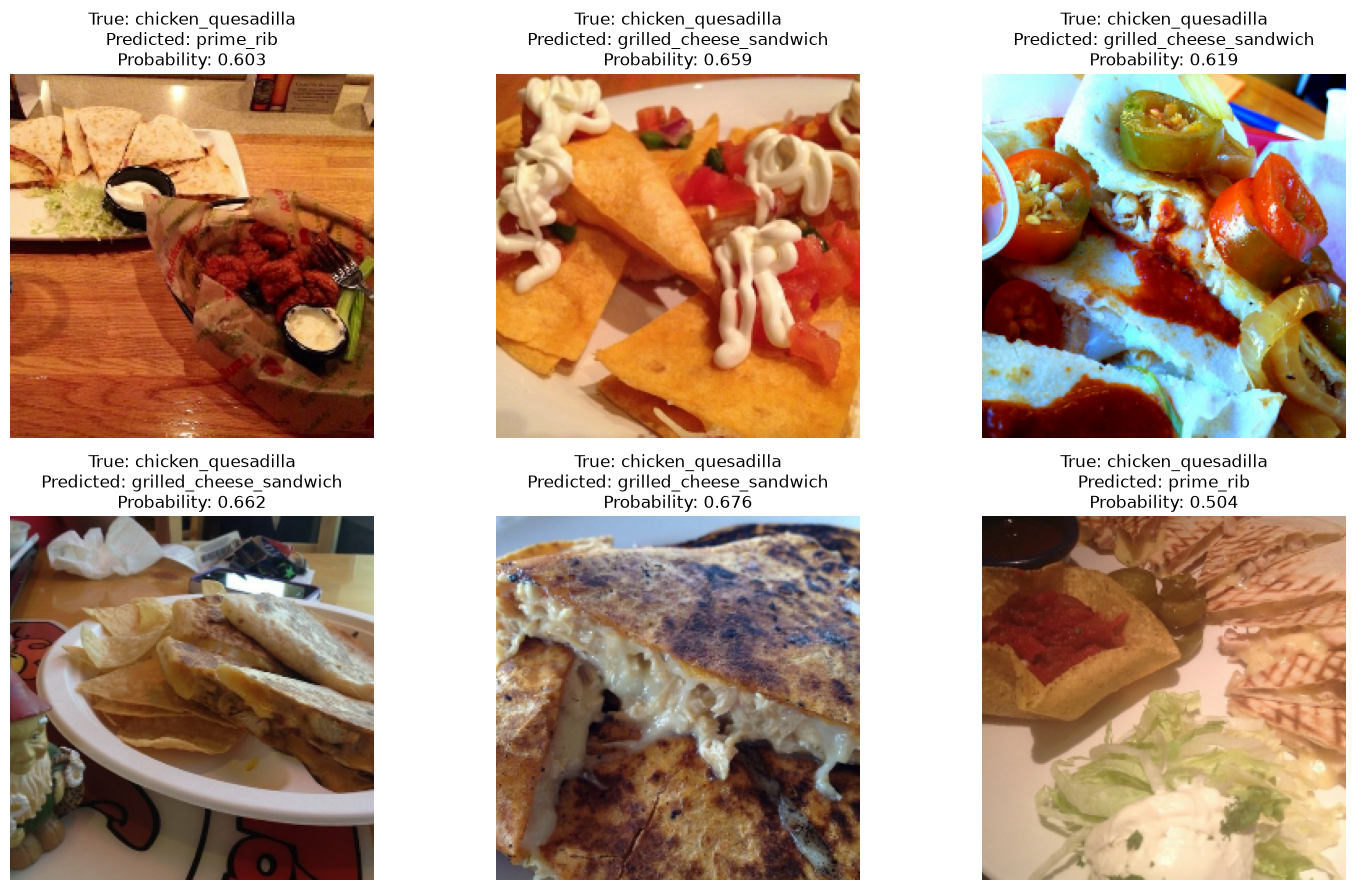

Кількість неправильних прогнозів: 35


In [31]:
# Знаходимо індекси неправильних прогнозів
wrong_indices = np.where(y_true != y_pred)[0][:6]

# Отримуємо зображення з тестової вибірки
test_images = np.concatenate(
    [x.numpy() for x, y in test_ds],
    axis=0
)

# Виводимо помилкові прогнози
fig, axes = plt.subplots(
    2, 3, figsize=(15, 9)
)

for ax, idx in zip(axes.flat, wrong_indices):
    ax.imshow(test_images[idx].astype("uint8"))

    true_class = class_names[y_true[idx]]
    predicted_class = class_names[y_pred[idx]]
    confidence = probabilities[idx].max()

    ax.set_title(
        f"True: {true_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Probability: {confidence:.3f}"
    )

    ax.axis("off")

# Прибираємо порожні місця, якщо помилок менше шести
for ax in axes.flat[len(wrong_indices):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Кількість неправильних прогнозів:", len(np.where(y_true != y_pred)[0]))

## Побудова графіків навчання ##

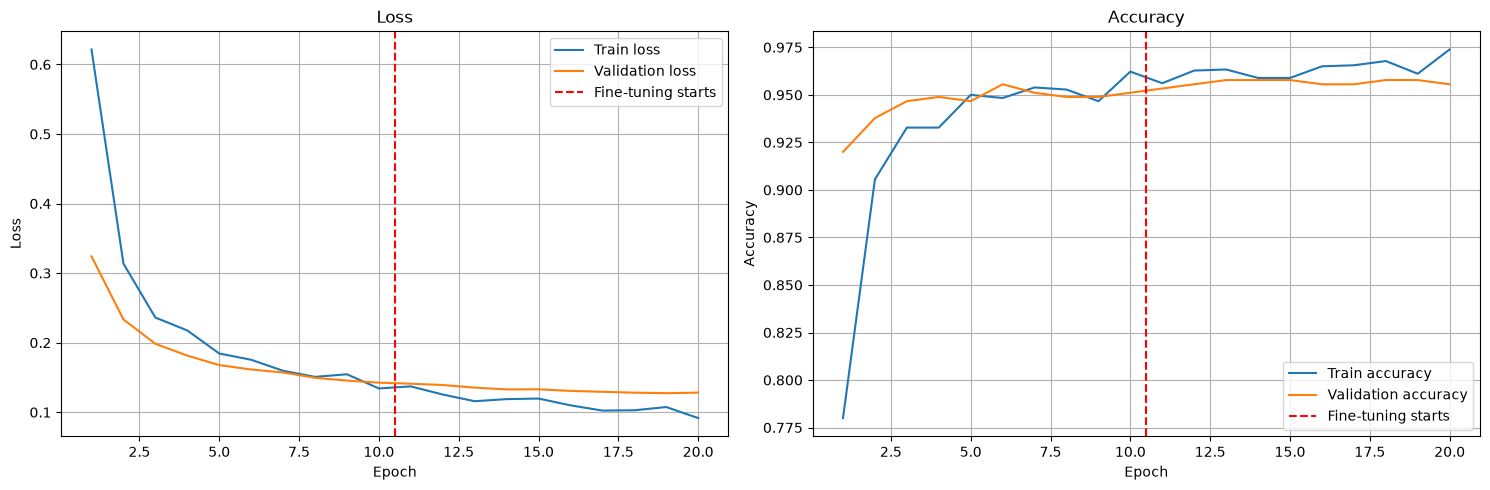

In [32]:
# Об'єднуємо результати двох етапів навчання
train_loss = (
    history_head.history["loss"] +
    history_fine.history["loss"]
)

val_loss = (
    history_head.history["val_loss"] +
    history_fine.history["val_loss"]
)

train_accuracy = (
    history_head.history["accuracy"] +
    history_fine.history["accuracy"]
)

val_accuracy = (
    history_head.history["val_accuracy"] +
    history_fine.history["val_accuracy"]
)

# Визначаємо межу між двома етапами
boundary = len(history_head.history["loss"])

epochs = range(1, len(train_loss) + 1)

# Створюємо два графіки
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Графік Loss
axes[0].plot(epochs, train_loss, label="Train loss")
axes[0].plot(epochs, val_loss, label="Validation loss")
axes[0].axvline(boundary + 0.5, color="red",
                linestyle="--", label="Fine-tuning starts")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

# Графік Accuracy
axes[1].plot(epochs, train_accuracy, label="Train accuracy")
axes[1].plot(epochs, val_accuracy, label="Validation accuracy")
axes[1].axvline(boundary + 0.5, color="red",
                linestyle="--", label="Fine-tuning starts")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

## Збереження результатів ##

In [33]:
best_model.save(OUT / "selected_model.keras")
metadata = {
    "tensorflow": tf.__version__, "keras": keras.__version__,
    "seed": SEED, "class_names": class_names,
    "image_size": [224, 224], "pixel_range": [0, 255],
    "backbone": "EfficientNetB0", "weights": "imagenet",
    "selected_stage": selected_stage,
    "comparison": comparison,
    "test_metrics": test_metrics,
}
(OUT / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8")


806